### Environment Setup (Local VS Code / WSL & Google Colab)

* **Local (VS Code / WSL):** The `try: from google.colab import drive` block fails immediately (`ImportError`), nothing is downloaded or reinstalled, and your local `.venv` environment—already configured via `uv sync --all-groups`—is used as is.
* **Google Colab:**
  * The Git repository is cloned and the current working directory switches to `handwritten_digits`.
  * `uv` reads `pyproject.toml` directly (eliminating the need for `requirements.txt`) and installs both production dependencies and the `dev` group (`scikit-learn`, `mlflow`, `dagshub`, `dvc`, `matplotlib`, `seaborn`, etc.).
  * `--exclude tensorflow` prevents `uv` from overwriting or re-downloading TensorFlow, preserving Google Colab's pre-installed GPU build and speeding up notebook startup.
  * `!dvc pull` then automatically retrieves your versioned datasets and models.

In [1]:
# 100% compatible (Google Colab & Local VS Code)


# == REMINDER: Update BRANCH below to match the active feature branch of this notebook ===
BRANCH = "feature/1_baseline"
# ========================================================================================

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Environment: Google Colab (Drive mounted)")

    # Automatic environment setup on Google Colab
    import os
    if not os.path.exists("handwritten_digits"):
        !git clone -b {BRANCH} https://github.com/bruno-coulet/handwritten_digits.git
    %cd handwritten_digits
    !pip install -q uv
    !uv pip install -q -r pyproject.toml --group dev --system --exclude tensorflow
    !uv pip install -q --no-deps -e . --system
    !dvc pull

except ImportError:
    print("Environment: Local (VS Code)")

Environment: Local (VS Code)


# Milestone 1: MNIST Data Exploration & Classical Baseline

**Objectives:**
1. Configure the runtime environment and connect **MLflow / DagsHub** experiment tracking.
2. Load the **MNIST** dataset, verify class balance, and visually inspect sample images.
3. Normalize pixel values and perform a reproducible **54,000 train / 6,000 validation** split (keeping the 10,000-image test set strictly untouched).
4. Train a **scikit-learn** baseline (Logistic Regression), measure validation error, inspect the confusion matrix, and log metrics and artifacts to DagsHub.

In [2]:
import os
import platform
import time

import dagshub
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import sklearn
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow import keras

from handwritten_digits.config import (
    EXPERIMENT_BASELINE,
    DAGSHUB_REPO_NAME,
    DAGSHUB_REPO_OWNER,
    FIGURES_DIR,
    RANDOM_SEED,
    HOLDOUT_DIR,
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    REPORTS_DIR,
)

/home/coule/Documents/projets/handwritten_digits/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1795016988.190179   62511 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795016988.755765   62511 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795016991.739860   62511 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### 1 - Reproducibility & DagsHub (MLflow) Connection

In [3]:
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Log library versions to ensure reproducibility
print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"TensorFlow   : {tf.__version__}")
print(f"MLflow       : {mlflow.__version__}")

Python       : 3.12.3
NumPy        : 2.5.5
Scikit-learn : 1.9.1
TensorFlow   : 2.21.0
MLflow       : 3.18.0


In [4]:
# If colab, get the ids from the colab secrets (in the left bar)
try:
    from google.colab import userdata
    os.environ["DAGSHUB_USER_TOKEN"] = userdata.get("DAGSHUB_USER_TOKEN")
except ImportError:
    pass

# Authenticate with DagsHub and configure MLflow tracking URI
dagshub.init(repo_owner=DAGSHUB_REPO_OWNER, repo_name=DAGSHUB_REPO_NAME, mlflow=True)

# ======== MLflow Experiment Setup ========
mlflow.set_experiment(EXPERIMENT_BASELINE)

# from handwritten_digits.config import EXPERIMENT_MLP
# mlflow.set_experiment(EXPERIMENT_MLP)

# from handwritten_digits.config import EXPERIMENT_CNN
# mlflow.set_experiment(EXPERIMENT_CNN)
# ==========

Accessing as bruno-coulet

Initialized MLflow to track repo "bruno-coulet/handwritten_digits"

Repository bruno-coulet/handwritten_digits initialized!

<Experiment: artifact_location='mlflow-artifacts:/f788ee55e5804c1392d694d5ef91db1f', creation_time=1795014406338, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1795014406338, lifecycle_stage='active', name='1_Baseline', tags={}, trace_location=None, workspace='default'>

### 2 - Loading & Exploring the MNIST Dataset

In [5]:
# Create directories if needed
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
HOLDOUT_DIR.mkdir(parents=True, exist_ok=True)

train_raw_path = RAW_DATA_DIR / "mnist_train_raw.npz"
holdout_path = HOLDOUT_DIR / "mnist_test_holdout.npz"

# load from disk (via DVC) if already present, else download via Keras and save
if train_raw_path.exists() and holdout_path.exists():
    with np.load(train_raw_path) as data:
        x_train_full, y_train_full = data["x"], data["y"]
    with np.load(holdout_path) as data:
        x_test, y_test = data["x"], data["y"]
    print("Dataset loaded from local DVC storage (data/raw & holdout).")
else:
    (x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()
    np.savez_compressed(train_raw_path, x=x_train_full, y=y_train_full)
    np.savez_compressed(holdout_path, x=x_test, y=y_test)
    print("Dataset downloaded via Keras and saved to data/raw & holdout.")


print("Full train set :", x_train_full.shape, y_train_full.shape)
print("Test set (held):", x_test.shape, y_test.shape)
print("Data type      :", x_train_full.dtype, "| min/max:", x_train_full.min(), x_train_full.max())

Dataset loaded from local DVC storage (data/raw & holdout).
Full train set : (60000, 28, 28) (60000,)
Test set (held): (10000, 28, 28) (10000,)
Data type      : uint8 | min/max: 0 255


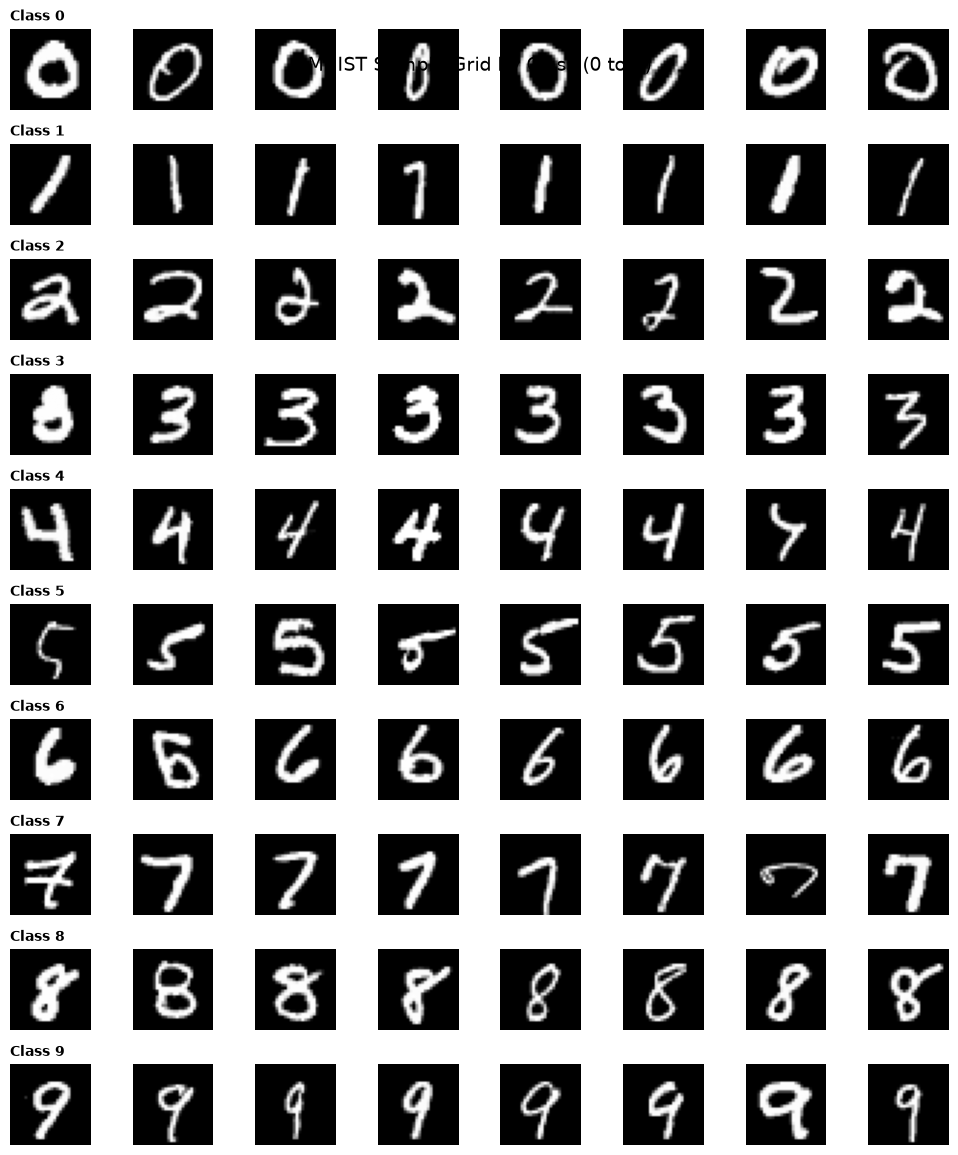

In [6]:
# Display a grid of random samples per digit class (0 to 9)
fig, axes = plt.subplots(10, 8, figsize=(10, 12))
for digit in range(10):
    digit_indices = np.where(y_train_full == digit)[0]
    rng = np.random.default_rng(RANDOM_SEED)
    chosen = rng.choice(digit_indices, size=8, replace=False)
    for col, idx in enumerate(chosen):
        axes[digit, col].imshow(x_train_full[idx], cmap="gray")
        axes[digit, col].axis("off")
        if col == 0:
            axes[digit, col].set_title(f"Class {digit}", loc="left", fontsize=10, fontweight="bold")

plt.suptitle("MNIST Sample Grid by Class (0 to 9)", fontsize=14, y=0.92)
plt.tight_layout()
plt.show()

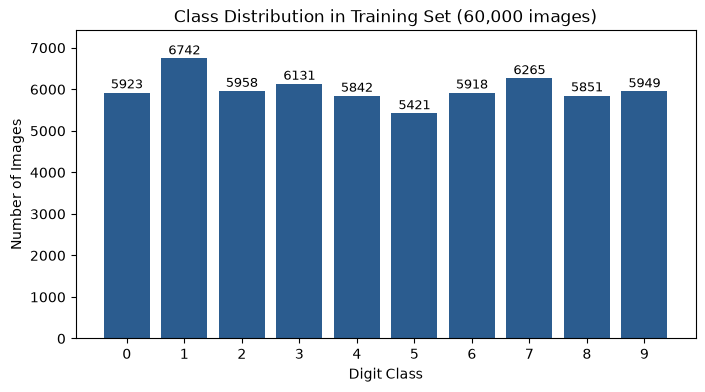

In [7]:
# Check class distribution across the 60,000 training images
classes, counts = np.unique(y_train_full, return_counts=True)

plt.figure(figsize=(8, 4))
bars = plt.bar(classes, counts, color="#2b5c8f")
plt.xticks(classes)
plt.xlabel("Digit Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution in Training Set (60,000 images)")
for bar, count in zip(bars, counts, strict=True):
    plt.text(bar.get_x() + bar.get_width() / 2, count + 100, str(count), ha="center", fontsize=9)
plt.ylim(0, max(counts) * 1.1)
plt.show()

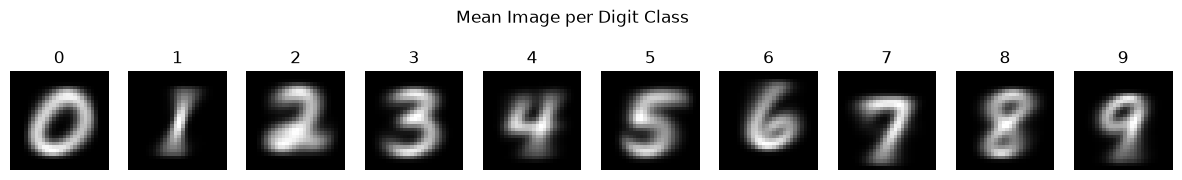

In [8]:
# Compute and plot the mean image per class
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    axes[c].imshow(x_train_full[y_train_full == c].mean(axis=0), cmap="gray")
    axes[c].set_title(str(c))
    axes[c].axis("off")
plt.suptitle("Mean Image per Digit Class", y=1.05)
plt.show()

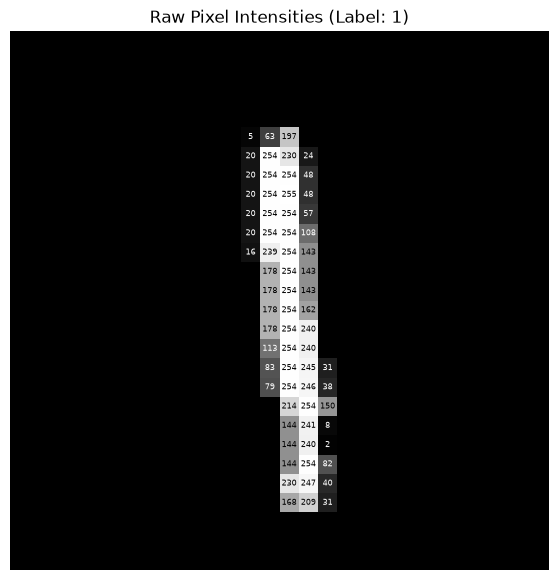

In [9]:
# Inspect raw pixel intensity values on a single sample
sample_idx = 8

plt.figure(figsize=(7, 7))
plt.imshow(x_train_full[sample_idx], cmap="gray")
for i in range(28):
    for j in range(28):
        v = x_train_full[sample_idx][i, j]
        if v > 0:
            plt.text(
                j, i, v, ha="center", va="center", fontsize=6,
                color="black" if v > 128 else "white"
            )
plt.title(f"Raw Pixel Intensities (Label: {y_train_full[sample_idx]})")
plt.axis("off")
plt.show()

### 3 - Preprocessing & Train / Validation / Test Split

* **Normalization**: Scale pixel values from `[0, 255]` to `[0.0, 1.0]` (`float32`).
* **Flattening**: Reshape `28 x 28` images into 1D feature vectors of length `784` for scikit-learn.
* **Stratified Split**: `54,000` training samples and `6,000` validation samples. The `10,000`-image test set remains strictly untouched during Milestone 1.

In [10]:
# Normalize pixel intensities to [0, 1]
x_train_norm = x_train_full.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

# Stratified split: 54,000 train / 6,000 validation
X_train_img, X_val_img, y_train, y_val = train_test_split(
    x_train_norm,
    y_train_full,
    test_size=6000,
    random_state=RANDOM_SEED,
    stratify=y_train_full,
)

# Persist processed 2D splits in data/processed/ for Milestones 2 & 3 (MLP & CNN)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
processed_path = PROCESSED_DATA_DIR / "mnist_split_54k_6k.npz"
if not processed_path.exists():
    np.savez_compressed(
        processed_path,
        X_train=X_train_img,
        y_train=y_train,
        X_val=X_val_img,
        y_val=y_val,
    )

# Flatten images to (N, 784) for classical ML models
X_train = X_train_img.reshape(len(X_train_img), -1)
X_val = X_val_img.reshape(len(X_val_img), -1)
X_test = x_test_norm.reshape(len(x_test_norm), -1)

print(f"X_train : {X_train.shape} | y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape}   | y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape}  | y_test  : {y_test.shape} (untouched in Milestone 1)")

X_train : (54000, 784) | y_train : (54000,)
X_val   : (6000, 784)   | y_val   : (6000,)
X_test  : (10000, 784)  | y_test  : (10000,) (untouched in Milestone 1)


### 4 - Baseline Training (Logistic Regression) & DagsHub Logging

Training duration   : 56.90 s
Validation Accuracy : 0.9215
Validation Error (%): 7.85 %


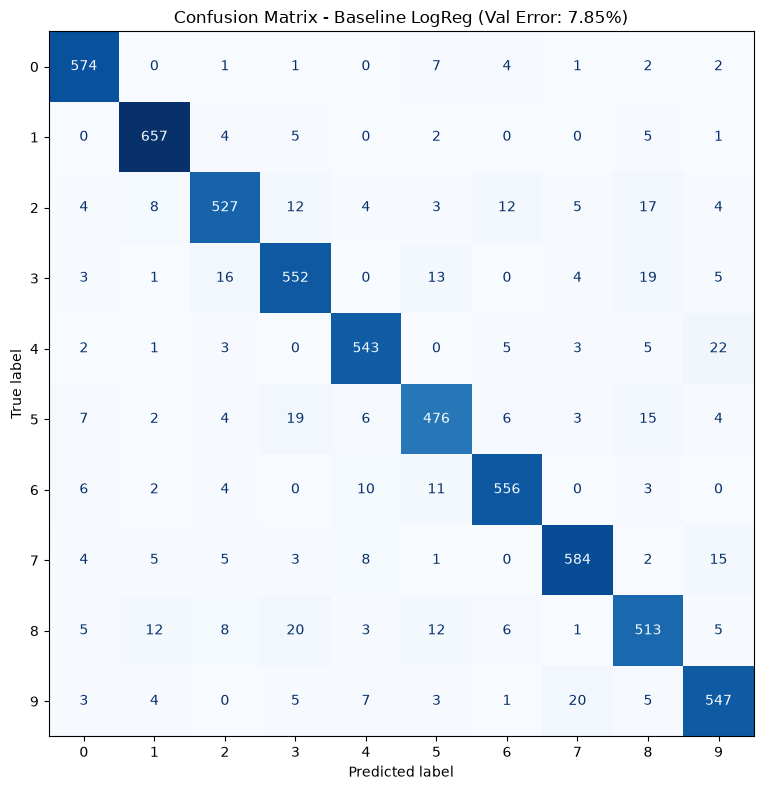


Top 10 misclassified pairs on the validation set (6,000 images):

  True: 4  -->  Predicted: 9  (22 errors)
  True: 9  -->  Predicted: 7  (20 errors)
  True: 8  -->  Predicted: 3  (20 errors)
  True: 5  -->  Predicted: 3  (19 errors)
  True: 3  -->  Predicted: 8  (19 errors)
  True: 2  -->  Predicted: 8  (17 errors)
  True: 3  -->  Predicted: 2  (16 errors)
  True: 5  -->  Predicted: 8  (15 errors)
  True: 7  -->  Predicted: 9  (15 errors)
  True: 3  -->  Predicted: 5  (13 errors)

Detailed Classification Report (Validation Set):

              precision    recall  f1-score   support

           0     0.9441    0.9696    0.9567       592
           1     0.9494    0.9748    0.9619       674
           2     0.9213    0.8842    0.9024       596
           3     0.8947    0.9005    0.8976       613
           4     0.9346    0.9298    0.9322       584
           5     0.9015    0.8782    0.8897       542
           6     0.9424    0.9392    0.9408       592
           7     0.9404    0.

2026/11/18 16:51:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 16:51:24 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run baseline_logistic_regression at: https://dagshub.com/bruno-coulet/handwritten_digits.mlflow/#/experiments/2/runs/04c3d1d6fe804f5b9cf30fcc28a9dca9
🧪 View experiment at: https://dagshub.com/bruno-coulet/handwritten_digits.mlflow/#/experiments/2


In [11]:
params = {
    "model_type": "LogisticRegression",
    "max_iter": 1000,
    "solver": "lbfgs",
    "C": 1.0,
    "seed": RANDOM_SEED,
    "train_size": len(X_train),
    "val_size": len(X_val),
    "scaling": "min_max_0_1",
}

with mlflow.start_run(run_name="baseline_logistic_regression"):
    # 1. Log hyperparameters and reproducibility metadata
    mlflow.log_params(params)
    mlflow.set_tag("milestone", EXPERIMENT_BASELINE)
    mlflow.set_tag("test_set_used", "False")

    # 2. Fit the baseline model
    start_time = time.time()
    clf = LogisticRegression(
        max_iter=params["max_iter"],
        solver=params["solver"],
        C=params["C"],
        random_state=RANDOM_SEED,
    )
    clf.fit(X_train, y_train)
    train_duration = time.time() - start_time

    # 3. Evaluate strictly on the validation set (6,000 images)
    val_preds = clf.predict(X_val)
    val_accuracy = (val_preds == y_val).mean()
    val_error_pct = (1.0 - val_accuracy) * 100

    mlflow.log_metric("val_accuracy", val_accuracy)
    mlflow.log_metric("val_error_pct", val_error_pct)
    mlflow.log_metric("training_duration_sec", train_duration)

    print(f"Training duration   : {train_duration:.2f} s")
    print(f"Validation Accuracy : {val_accuracy:.4f}")
    print(f"Validation Error (%): {val_error_pct:.2f} %")

    # 4. Generate and log confusion matrix artifact
    cm = confusion_matrix(y_val, val_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    plt.title(f"Confusion Matrix - Baseline LogReg (Val Error: {val_error_pct:.2f}%)")
    plt.tight_layout()

    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    cm_path = FIGURES_DIR / "milestone1_baseline_confusion_matrix.png"
    plt.savefig(cm_path, dpi=150)
    plt.show()

    mlflow.log_artifact(str(cm_path))

    # 5. Extract top 10 misclassifications & log classification report artifact
    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)
    flat_indices = np.argsort(cm_no_diag.ravel())[::-1][:10]

    report_lines = ["Top 10 misclassified pairs on the validation set (6,000 images):\n"]
    for idx in flat_indices:
        true_label, pred_label = divmod(idx, 10)
        count = cm_no_diag[true_label, pred_label]
        report_lines.append(f"  True: {true_label}  -->  Predicted: {pred_label}  ({count} errors)")

    report_lines.append("\nDetailed Classification Report (Validation Set):\n")
    report_lines.append(classification_report(y_val, val_preds, digits=4))
    full_report_text = "\n".join(report_lines)

    print("\n" + full_report_text)

    REPORTS_DIR.mkdir(parents=True, exist_ok=True)
    report_path = REPORTS_DIR / "milestone1_baseline_report.txt"
    report_path.write_text(full_report_text, encoding="utf-8")
    mlflow.log_artifact(str(report_path))

    # 6. Log trained baseline model with input signature example
    mlflow.sklearn.log_model(
        sk_model=clf,
        artifact_path="baseline_model",
        input_example=X_val[:5],
)

### 5 - Baseline Error Analysis (Most Confused Pairs)

In [12]:
# Extract top 10 most frequent misclassifications (True -> Predicted)
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

flat_indices = np.argsort(cm_no_diag.ravel())[::-1][:10]
print("Top 10 misclassified pairs on the validation set (6,000 images):\n")
for idx in flat_indices:
    true_label, pred_label = divmod(idx, 10)
    count = cm_no_diag[true_label, pred_label]
    print(f"  True: {true_label}  -->  Predicted: {pred_label}  ({count} errors)")

print("\nDetailed Classification Report (Validation Set):\n")
print(classification_report(y_val, val_preds, digits=4))

Top 10 misclassified pairs on the validation set (6,000 images):

  True: 4  -->  Predicted: 9  (22 errors)
  True: 9  -->  Predicted: 7  (20 errors)
  True: 8  -->  Predicted: 3  (20 errors)
  True: 5  -->  Predicted: 3  (19 errors)
  True: 3  -->  Predicted: 8  (19 errors)
  True: 2  -->  Predicted: 8  (17 errors)
  True: 3  -->  Predicted: 2  (16 errors)
  True: 5  -->  Predicted: 8  (15 errors)
  True: 7  -->  Predicted: 9  (15 errors)
  True: 3  -->  Predicted: 5  (13 errors)

Detailed Classification Report (Validation Set):

              precision    recall  f1-score   support

           0     0.9441    0.9696    0.9567       592
           1     0.9494    0.9748    0.9619       674
           2     0.9213    0.8842    0.9024       596
           3     0.8947    0.9005    0.8976       613
           4     0.9346    0.9298    0.9322       584
           5     0.9015    0.8782    0.8897       542
           6     0.9424    0.9392    0.9408       592
           7     0.9404    0.9

#### Interpretation & Hypothesis
* **Validation Error Rate**: ~7.5% to 8.0% error on the validation set (~92% accuracy).
* **Most Confused Pairs**: The highest confusion rates typically occur between **(4 and 9)**, **(3 and 5)**, **(5 and 8)**, and **(7 and 9)**.
* **Hypothesis**: Logistic Regression is a linear classifier that assigns an independent weight to each pixel coordinate `(i, j)` without spatial awareness. Digits such as a closed-top `4` and `9`, or `3` and `5`, share a large overlap of active pixels in the center of the $28 \times 28$ grid and differ only by localized loops or stroke angles.